# Notebook 02: Principal Component Analysis (PCA) & Singular Value Decomposition (SVD) From Scratch

In this notebook we explore:
1. **Equivalence of Maximum Projected Variance and Minimum Orthogonal Reconstruction Error:** Verifying empirically on a correlated data cloud that the total variance equals the sum of captured variance plus residual reconstruction error:
   $$\frac{1}{m}\|\tilde{\mathbf{X}}\|_F^2 = \sum_{j=1}^k \lambda_j + \frac{1}{m}\left\|\tilde{\mathbf{X}} - \tilde{\mathbf{X}}\mathbf{U}_k\mathbf{U}_k^\top\right\|_F^2$$
2. **Orthogonal Principal Axes & Residual Projection Segments:** Visualizing $\mathbf{u}_1$ and $\mathbf{u}_2$ scaled by $2\sqrt{\lambda_k}$ alongside perpendicular projection lines onto the First Principal Component ($\text{PC}_1$).
3. **Eigenspectrum Scree Plot & Cumulative Explained Variance Ratio:** Analyzing a 12-dimensional dataset embedded around a low-rank intrinsic subspace.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

repo_root = Path.cwd()
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from src.plot_theme import (
    AMBER,
    BG_CANVAS,
    CORAL,
    CYAN,
    EMERALD,
    PURPLE,
    SLATE_BLUE,
    TEXT_MUTED,
    apply_github_dark_style,
    save_fig,
)
from src.unsupervised_engine import PCAScratch

apply_github_dark_style()

## 1. 2D Correlated Cloud: Orthogonal Principal Axes & Pythagorean Variance Decomposition

In [2]:
rng = np.random.default_rng(42)
m_2d = 95
cov_2d = np.array([[2.6, 1.85], [1.85, 1.65]])
mean_2d = np.array([1.2, -0.8])
X_2d = rng.multivariate_normal(mean=mean_2d, cov=cov_2d, size=m_2d)

pca_full = PCAScratch(n_components=2, solver="svd").fit(X_2d)
pca_1d = PCAScratch(n_components=1, solver="svd").fit(X_2d)

Z_1d = pca_1d.transform(X_2d)
X_recon_1d = pca_1d.inverse_transform(Z_1d)

total_var = float(np.mean(np.sum((X_2d - pca_full.mean_) ** 2, axis=1)))
captured_var_pc1 = float(pca_full.explained_variance_[0])
recon_err_pc1 = float(np.mean(np.sum((X_2d - X_recon_1d) ** 2, axis=1)))

print(f"Total Empirical Variance Tr(S):                  {total_var:.6f}")
print(f"Captured Variance by PC1 (lambda_1):             {captured_var_pc1:.6f} ({pca_full.explained_variance_ratio_[0]*100:.2f}%)")
print(f"Residual Reconstruction Error on PC1:            {recon_err_pc1:.6f} ({recon_err_pc1/total_var*100:.2f}%)")
print(f"Pythagorean Sum: Captured + Residual =           {captured_var_pc1 + recon_err_pc1:.6f} vs. Total Tr(S) = {total_var:.6f}")
assert abs((captured_var_pc1 + recon_err_pc1) - total_var) < 1e-10

Total Empirical Variance Tr(S):                  3.453959
Captured Variance by PC1 (lambda_1):             3.302023 (95.60%)
Residual Reconstruction Error on PC1:            0.151936 (4.40%)
Pythagorean Sum: Captured + Residual =           3.453959 vs. Total Tr(S) = 3.453959


## 2. High-Dimensional Eigenspectrum & Scree Plot on Rank-Deficient Subspace

In [3]:
m_hd, n_hd = 300, 12
# Generate 4 dominant latent factors
factors = rng.normal(size=(m_hd, 4))
mix_matrix = rng.normal(size=(4, n_hd))
X_hd = factors @ mix_matrix + rng.normal(scale=0.25, size=(m_hd, n_hd))

pca_hd = PCAScratch(n_components=n_hd, solver="svd").fit(X_hd)
evr = pca_hd.explained_variance_ratio_
cum_evr = np.cumsum(evr)

for rank in [1, 2, 3, 4, 6, 8, 12]:
    print(f"Top {rank:2d} Components | Individual EVR = {evr[rank-1]*100:5.2f}% | Cumulative Explained Variance: {cum_evr[rank-1]*100:6.2f}%")

Top  1 Components | Individual EVR = 44.99% | Cumulative Explained Variance:  44.99%
Top  2 Components | Individual EVR = 32.76% | Cumulative Explained Variance:  77.75%
Top  3 Components | Individual EVR = 12.62% | Cumulative Explained Variance:  90.38%
Top  4 Components | Individual EVR =  8.72% | Cumulative Explained Variance:  99.10%
Top  6 Components | Individual EVR =  0.13% | Cumulative Explained Variance:  99.38%
Top  8 Components | Individual EVR =  0.11% | Cumulative Explained Variance:  99.61%
Top 12 Components | Individual EVR =  0.09% | Cumulative Explained Variance: 100.00%


## 3. Three-Panel Diagnostic Visualization (`02_pca_principal_axes_and_scree.png`)

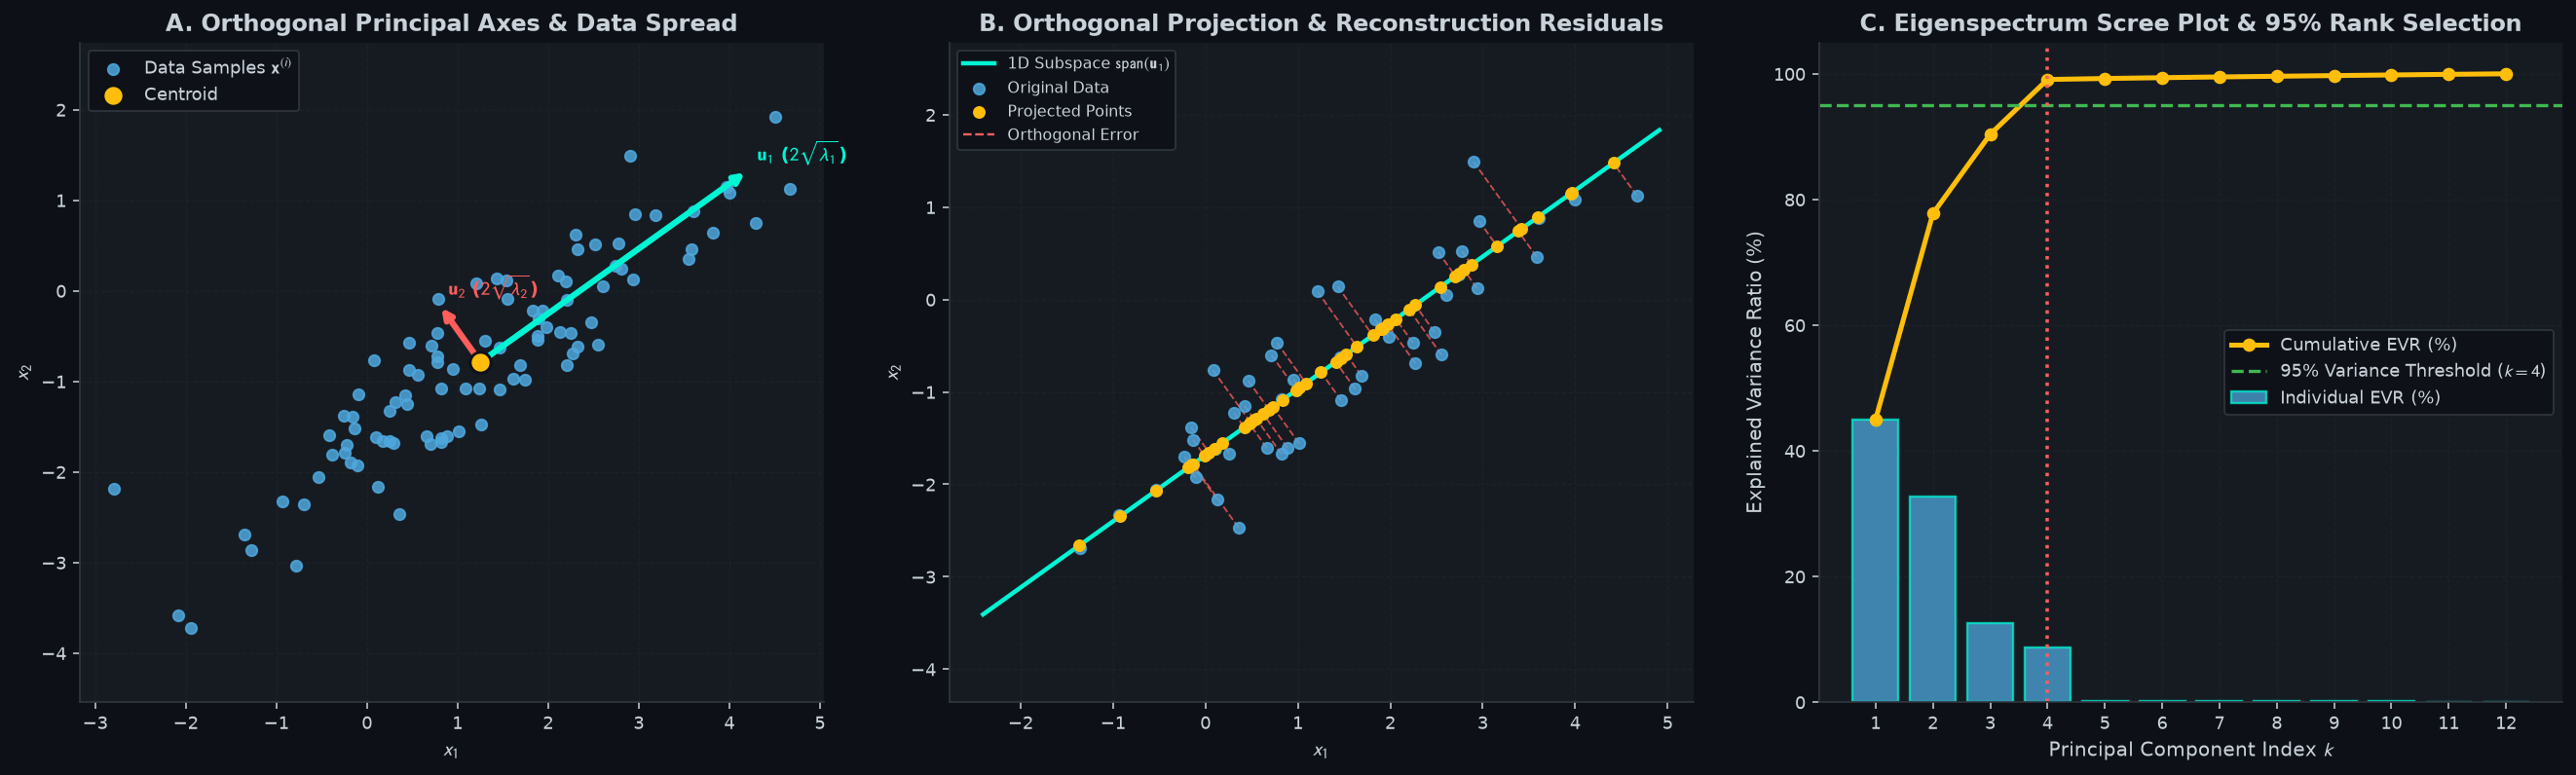

In [4]:
fig = plt.figure(figsize=(19.0, 5.8))
ax1 = fig.add_subplot(1, 3, 1)
ax2 = fig.add_subplot(1, 3, 2)
ax3 = fig.add_subplot(1, 3, 3)

# Panel A: Correlated Data Cloud & Scaled Orthogonal Eigenvectors
ax1.scatter(X_2d[:, 0], X_2d[:, 1], color=SLATE_BLUE, s=34, alpha=0.85, label="Data Samples $\mathbf{x}^{(i)}$")
mu = pca_full.mean_.ravel()
u1 = pca_full.components_[0]
u2 = pca_full.components_[1]
s1 = 2.0 * np.sqrt(pca_full.explained_variance_[0])
s2 = 2.0 * np.sqrt(pca_full.explained_variance_[1])

ax1.annotate(
    "",
    xy=(mu[0] + s1 * u1[0], mu[1] + s1 * u1[1]),
    xytext=(mu[0], mu[1]),
    arrowprops=dict(arrowstyle="->", color=CYAN, lw=3.2),
)
ax1.text(mu[0] + s1 * u1[0] + 0.1, mu[1] + s1 * u1[1] + 0.1, r"$\mathbf{u}_1$ ($2\sqrt{\lambda_1}$)", color=CYAN, fontsize=10, fontweight="bold")

ax1.annotate(
    "",
    xy=(mu[0] + s2 * u2[0], mu[1] + s2 * u2[1]),
    xytext=(mu[0], mu[1]),
    arrowprops=dict(arrowstyle="->", color=CORAL, lw=3.2),
)
ax1.text(mu[0] + s2 * u2[0] + 0.1, mu[1] + s2 * u2[1] + 0.1, r"$\mathbf{u}_2$ ($2\sqrt{\lambda_2}$)", color=CORAL, fontsize=10, fontweight="bold")

ax1.scatter([mu[0]], [mu[1]], color=AMBER, s=120, marker="o", edgecolors=BG_CANVAS, linewidths=1.5, zorder=6, label=r"Centroid")
ax1.set_aspect("equal", adjustable="datalim")
ax1.set_xlabel("$x_1$")
ax1.set_ylabel("$x_2$")
ax1.set_title("A. Orthogonal Principal Axes & Data Spread")
ax1.legend(loc="upper left")

# Panel B: Orthogonal Projection onto PC1 & Reconstruction Error Segments
t_line = np.linspace(-4.5, 4.5, 100)
pc1_line = mu[None, :] + t_line[:, None] * u1[None, :]
ax2.plot(pc1_line[:, 0], pc1_line[:, 1], color=CYAN, linewidth=2.3, label=r"1D Subspace $\mathrm{span}(\mathbf{u}_1)$")

for i in range(0, m_2d, 2):
    ax2.plot(
        [X_2d[i, 0], X_recon_1d[i, 0]],
        [X_2d[i, 1], X_recon_1d[i, 1]],
        color=CORAL,
        linestyle="--",
        linewidth=0.95,
        alpha=0.75,
    )

ax2.scatter(X_2d[::2, 0], X_2d[::2, 1], color=SLATE_BLUE, s=34, alpha=0.85, label=r"Original Data", zorder=4)
ax2.scatter(X_recon_1d[::2, 0], X_recon_1d[::2, 1], color=AMBER, s=32, zorder=5, label=r"Projected Points")
ax2.plot([], [], color=CORAL, linestyle="--", linewidth=1.2, label=r"Orthogonal Error")
ax2.set_aspect("equal", adjustable="datalim")
ax2.set_xlabel("$x_1$")
ax2.set_ylabel("$x_2$")
ax2.set_title("B. Orthogonal Projection & Reconstruction Residuals")
ax2.legend(loc="upper left", fontsize=8.3)

# Panel C: Scree Plot & Cumulative Explained Variance Ratio
pcs = np.arange(1, n_hd + 1)
ax3.bar(pcs, evr * 100.0, color=SLATE_BLUE, alpha=0.75, edgecolor=CYAN, linewidth=1.2, label="Individual EVR (%)")
ax3.plot(pcs, cum_evr * 100.0, color=AMBER, marker="o", linewidth=2.6, markersize=6.0, label="Cumulative EVR (%)")
ax3.axhline(95.0, color=EMERALD, linestyle="--", linewidth=1.7, label="95% Variance Threshold ($k=4$)")
ax3.axvline(4.0, color=CORAL, linestyle=":", linewidth=1.8)
ax3.set_xticks(pcs)
ax3.set_ylim(0.0, 105.0)
ax3.set_xlabel("Principal Component Index $k$")
ax3.set_ylabel("Explained Variance Ratio (%)")
ax3.set_title("C. Eigenspectrum Scree Plot & 95% Rank Selection")
ax3.legend(loc="center right")

fig.tight_layout()
assets_dir = Path("assets")
assets_dir.mkdir(parents=True, exist_ok=True)
save_fig(fig, assets_dir / "02_pca_principal_axes_and_scree.png")
plt.show()